# Defining custom Image Dataset loader and usage

In [1]:
!pip install -q "pillow>=8.0,<13.0"

In [2]:
!pip install -q -U gdown

In [43]:
import os
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from torchvision import transforms

import torch
from torch.utils.data import Dataset, DataLoader

`from torchvision import transforms` provides tools to **resize**, **crop**, **rotate**, **normalize**, **convert**, and **augment** images before feeding them into a neural network.

The original images might have:
- Different dimensions (e.g., 128 × 128, 256 × 256).
- Different pixel formats.
- Different brightness and contrast.
- Pixel values ranging from 0 to 255.

However, neural network generally expects images in a consistent tensor format and shape.

`torchvision.transforms` helps prepare the images.

**Common Transformation**  

| Transformation | Purpose |
|----------------|---------|
| `Resize()` | Resize images to a specified dimension |
| `CenterCrop()` | Crop the center portion of an image |
| `RandomCrop()`	| Randomly crop an image |
| `RandomHorizontalFlip()` | Randomly flip images horizontally |
| `RandomRotation()` | Randomly rotate images |
| `ToTensor()` | Convert an image into a PyTorch tensor |
| `Normalize()` | Normalize image pixel values |
| `ColorJitter()` | Randomly adjust brightness, contrast, saturation, and hue |

In [4]:
# Download file from Google Drive
!gdown "https://drive.google.com/file/d/1FZO4ojM03tP1lTaiVHShzDX5oMDTi3oZ/view?usp=sharing"

Downloading...
From (original): https://drive.google.com/uc?id=1FZO4ojM03tP1lTaiVHShzDX5oMDTi3oZ
From (redirected): https://drive.google.com/uc?id=1FZO4ojM03tP1lTaiVHShzDX5oMDTi3oZ&confirm=t&uuid=773fefd7-e2e7-452d-949e-0e3fc0a19219
To: /content/Classification_dataset_v3.zip
100% 256M/256M [00:04<00:00, 52.5MB/s]


In [5]:
# Unzip the zipped file
!unzip "/content/Classification_dataset_v3.zip"

Archive:  /content/Classification_dataset_v3.zip
   creating: Classification_dataset_v3/
  inflating: Classification_dataset_v3/Dataset_info.txt  
   creating: Classification_dataset_v3/images/
   creating: Classification_dataset_v3/images/test/
   creating: Classification_dataset_v3/images/test/Cat/
  inflating: Classification_dataset_v3/images/test/Cat/cat_1000.jpg  
  inflating: Classification_dataset_v3/images/test/Cat/cat_1001.jpg  
  inflating: Classification_dataset_v3/images/test/Cat/cat_1002.jpg  
  inflating: Classification_dataset_v3/images/test/Cat/cat_1003.jpg  
  inflating: Classification_dataset_v3/images/test/Cat/cat_1004.jpg  
  inflating: Classification_dataset_v3/images/test/Cat/cat_1005.jpg  
  inflating: Classification_dataset_v3/images/test/Cat/cat_1006.jpg  
  inflating: Classification_dataset_v3/images/test/Cat/cat_1007.jpg  
  inflating: Classification_dataset_v3/images/test/Cat/cat_1008.jpg  
  inflating: Classification_dataset_v3/images/test/Cat/cat_1009.jpg 

In [6]:
train_dir = '/content/Classification_dataset_v3/images/train'
classes = os.listdir(train_dir)
classes

['Cat', 'Person', 'Dog']

In [7]:
# For "__init__()"
class_name = {}
img_paths = []
labels = []
for label, class_ in enumerate(classes):
    class_name[label] = class_
    class_path = os.path.join(train_dir, class_)
    # print(class_path)
    # print(os.listdir(class_path)) # return image names under each directories

    # Append all directories of images and related class labels from "train" folder
    for img_name in os.listdir(class_path):
        img_paths.append(os.path.join(class_path, img_name))
        labels.append(label)

print(class_name)
print(img_paths)
print(labels)
print(len(img_paths))
print(len(labels))

{0: 'Cat', 1: 'Person', 2: 'Dog'}
['/content/Classification_dataset_v3/images/train/Cat/cat_0193.jpg', '/content/Classification_dataset_v3/images/train/Cat/cat_0560.jpg', '/content/Classification_dataset_v3/images/train/Cat/cat_0656.jpg', '/content/Classification_dataset_v3/images/train/Cat/cat_0166.jpg', '/content/Classification_dataset_v3/images/train/Cat/cat_0124.jpg', '/content/Classification_dataset_v3/images/train/Cat/cat_0344.jpg', '/content/Classification_dataset_v3/images/train/Cat/cat_0402.jpg', '/content/Classification_dataset_v3/images/train/Cat/cat_0080.jpg', '/content/Classification_dataset_v3/images/train/Cat/cat_0162.jpg', '/content/Classification_dataset_v3/images/train/Cat/cat_0071.jpg', '/content/Classification_dataset_v3/images/train/Cat/cat_0209.jpg', '/content/Classification_dataset_v3/images/train/Cat/cat_0564.jpg', '/content/Classification_dataset_v3/images/train/Cat/cat_0742.jpg', '/content/Classification_dataset_v3/images/train/Cat/cat_0599.jpg', '/content/Cla

0
Compose(
    Resize(size=(128, 128), interpolation=bilinear, max_size=None, antialias=True)
    ToTensor()
)


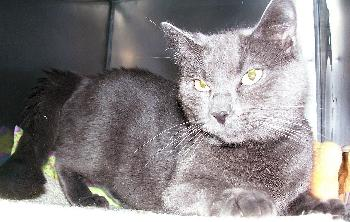

In [11]:
# For "__getitem__()"
idx = 0
image_path = img_paths[idx]
img = Image.open(image_path).convert('RGB')
label = labels[idx]

# Define a sequence of image transformations using transforms.Compose()
image = transforms.Compose([

                    # Resize the input image to 128 × 128 pixels
                    # Ensures all images have the same dimensions
                    transforms.Resize((128, 128)),

                    # Convert the image into a PyTorch tensor
                    # Converts pixel values from the range [0, 255] to [0.0, 1.0]
                    transforms.ToTensor()

                    ])
print(label)
print(image)
img

In [61]:
class ImageDataset(Dataset):
    def __init__(self, img_dir, transform=None):
        self.image_dir = img_dir     # directory of specific images directory
        self.image_paths = []        # collection of image paths
        self.labels = []             # images labelling
        self.class_name = {}         # matching between labels and class_
        self.transform = transform   # image transformation method

        # Get all paths of each class (Dog, Cat, Person)
        for label, class_ in enumerate(os.listdir(self.image_dir)):
            self.class_name[label] = class_
            class_path = os.path.join(self.image_dir, class_)

            # Append all directories of images and related class labels from "train" folder
            for img_name in os.listdir(class_path):
                self.image_paths.append(os.path.join(class_path, img_name))
                self.labels.append(label)

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, idx):
        image_path = self.image_paths[idx]
        image = Image.open(image_path).convert('RGB')
        label = self.labels[idx]

        if self.transform:
            image = self.transform(image)

        return image, label

In [28]:
# Define a sequence of image transformations using transforms.Compose()
transform = transforms.Compose([

                    # Resize the input image to 128 × 128 pixels
                    # Ensures all images have the same dimensions
                    transforms.Resize((128, 128)),

                    # Convert the image into a PyTorch tensor
                    # Converts pixel values from the range [0, 255] to [0.0, 1.0]
                    transforms.ToTensor()

                    ])

In [62]:
train_image_dir = '/content/Classification_dataset_v3/images/train'
test_image_dir = '/content/Classification_dataset_v3/images/test'

train_image_dataset = ImageDataset(img_dir=train_image_dir, transform=transform)
test_image_dataset = ImageDataset(img_dir=test_image_dir, transform=transform)

In [63]:
train_image_loader = DataLoader(dataset=train_image_dataset, batch_size=32, shuffle=True)
test_image_loader = DataLoader(dataset=test_image_dataset, batch_size=32, shuffle=True)

In [32]:
train_image_loader.__len__()

95

In [42]:
# Print out for first five 32 batches of images
for _, (img, label) in enumerate(train_image_loader):
    if _ < 5:
        print(f"{_+1}. Image shape: {img.shape} | Label shape: {label.shape}")
    else: break

1. Image shape: torch.Size([32, 3, 128, 128]) | Label shape: torch.Size([32])
2. Image shape: torch.Size([32, 3, 128, 128]) | Label shape: torch.Size([32])
3. Image shape: torch.Size([32, 3, 128, 128]) | Label shape: torch.Size([32])
4. Image shape: torch.Size([32, 3, 128, 128]) | Label shape: torch.Size([32])
5. Image shape: torch.Size([32, 3, 128, 128]) | Label shape: torch.Size([32])


This represents a 4-dimensional tensor containing 32 images.
| Dimension | Value	| Meaning |
|-----------|-------|---------|
|0	| 32 | Number of images in the batch |
|1	| 3 | Number of color channels (RGB) |
|2	| 128 | Image height |
|3	| 128 | Image width |

In [49]:
# Check "class_name" of each loaded dataset
print(train_image_dataset.class_name)
print(test_image_dataset.class_name)

{0: 'Cat', 1: 'Person', 2: 'Dog'}
{0: 'Cat', 1: 'Person', 2: 'Dog'}


torch.Size([32, 3, 128, 128]) torch.Size([32])
(3, 128, 128)
Cat
(128, 128, 3)


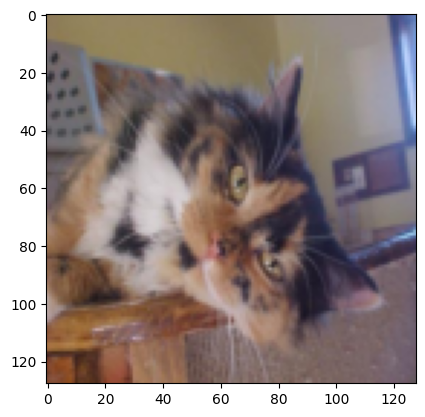

In [69]:
# Iterate through the training DataLoader one batch at a time
for images, labels in train_image_loader:

    # Display: images = [32, 3, 128, 128], labels = [32]
    print(images.shape, labels.shape)

    # Retrieve the first image from the batch
    img = images[0].numpy() # convert PyTorch tensor into Numpy array

    # Display image: (3, 128, 128) → Channels, Height, Width
    print(img.shape)

    # Retrieve the label of the first image
    label = labels[0].item() # .item() converts a single-element tensor into a Python integer

    # Convert the numerical label into its corresponding class name
    print(train_image_dataset.class_name[label]) # 0 → Cat, 1 → Person, 2 → Dog

    # Rearrange dimensions → (Channels, Height, Width) to (Height, Width, Channels)
    # Matplotlib expects the image format (H, W, C) for RGB images
    img = np.transpose(img, (1, 2, 0))

    # Display the new image shape
    print(img.shape) # (128, 128, 3)

    # Display the image using Matplotlib
    # vmin and vmax define the displayed intensity range
    plt.imshow(img, vmin=0, vmax=255)

    # Stop after processing the first batch
    break